In [1]:
# ============================================================
# CELL 1 — Imports, configuration, and path setup
# ============================================================
# WTI & Brent Price Monitor
# Sources: yfinance (futures) + EIA API (spot cross-reference)
# ─────────────────────────────────────────────────────────────

# Standard library
import sys
import os
import datetime as dt
from pathlib import Path

# Data
import pandas as pd
import numpy as np

# Market data
import yfinance as yf

# HTTP
import requests

# Visualization
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
from matplotlib.gridspec import GridSpec

# Display settings
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
plt.style.use("seaborn-v0_8-darkgrid")

# ── Path setup ───────────────────────────────────────────────
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import config

API_KEY   = config.EIA_API_KEY
BASE_URL  = "https://api.eia.gov/v2"
CHART_DIR = PROJECT_ROOT / "charts"
DATA_DIR  = PROJECT_ROOT / "data"

# ── Price data configuration ─────────────────────────────────
# yfinance tickers — both track front-month by delivery month.
# NOTE: Brent futures expire ~3 weeks before the WTI contract
# for the same delivery month, so continuous series elsewhere
# (TradingView BRN1!, Google) may roll Brent forward while WTI
# is still on the prior month. Our spread is same-delivery-month,
# which strips out calendar-spread contamination. Expect it to
# read WIDER than quoted "front-month" spreads during roll weeks.
WTI_TICKER   = "CL=F"    # front-month WTI  (currently CLX26)
BRENT_TICKER = "BZ=F"    # front-month Brent (currently BZX26)
WTI_TICKER   = "CL=F"    # WTI crude front-month futures //typical to use front month, it is generally "next month" due to expiration dates of futures contracts
BRENT_TICKER = "BZ=F"    # Brent crude front-month futures

# EIA spot price series (weekly, used as cross-reference)
# These are the official EIA weekly spot price series
EIA_WTI_ROUTE = "/petroleum/pri/spt/data/"

# How far back to fetch — yfinance goes to early 1980s for WTI
PRICE_START = "2007-01-01"   # Brent data quality starts ~1987
END_DATE    = dt.date.today()

# Rolling window for spread statistics
SPREAD_WINDOW_DAYS = 252     # ~1 trading year for rolling stats
RECENT_DAYS        = 365 * 3 # 3 years for main price chart focus

# ── Cache settings ───────────────────────────────────────────
# On first run, full history is downloaded and cached to CSV.
# On subsequent runs, we load from cache and only fetch recent
# data to top it up — keeps refresh time under 5 seconds.
WTI_CACHE   = DATA_DIR / "wti_price_cache.csv"
BRENT_CACHE = DATA_DIR / "brent_price_cache.csv"

# ── Sanity check ─────────────────────────────────────────────
print("=" * 58)
print("  WTI & Brent Price Monitor — configuration loaded")
print("=" * 58)
print(f"  Project root  : {PROJECT_ROOT}")
print(f"  API key       : {API_KEY[:6]}{'*' * 20}")
print(f"  WTI ticker    : {WTI_TICKER}")
print(f"  Brent ticker  : {BRENT_TICKER}")
print(f"  Price history : {PRICE_START} → {END_DATE}")
print(f"  Spread window : {SPREAD_WINDOW_DAYS} trading days")
print(f"  Cache dir     : {DATA_DIR}")
print("=" * 58)

  WTI & Brent Price Monitor — configuration loaded
  Project root  : c:\Users\mackt\Python Projects\oil_gas_tools
  API key       : K8wjSh********************
  WTI ticker    : CL=F
  Brent ticker  : BZ=F
  Price history : 2007-01-01 → 2026-09-26
  Spread window : 252 trading days
  Cache dir     : c:\Users\mackt\Python Projects\oil_gas_tools\data


In [2]:
# ============================================================
# CELL 2 — Caching price fetch function
# ============================================================
# Why caching matters here:
#  yfinance downloading 35+ years of daily price data takes
#  5-15 seconds and hammers Yahoo's servers on every run.
#  Instead we: download once -> save to CSV -> on future runs
#  load from CSV and only fetch data newer than the last 
#  cached date. Refresh time drops to under 2 seconds!

# This pattern (cache + incremental update) is standard in
# any data pipeline that pulls from a rate-limited source.
# ─────────────────────────────────────────────────────────────

def fetch_price_with_cache(
    ticker: str,
    cache_path: Path,
    start: str,
    end: dt.date,
    price_col: str = "Close",
) -> (pd.DataFrame, bool):
    """
    Fetch daily closing prices for a ticker via yfinance,
    using a local CSV cache for speed on repeat runs.

    Parameters
    ----------
    ticker     : yfinance ticker string e.g. 'CL=F'
    cache_path : Path to local CSV cache file
    start      : earliest date to fetch 'YYYY-MM-DD'
    end        : latest date (today usually)
    price_col  : which OHLCV column to keep (default Close)

    Returns
    -------
    pd.DataFrame with columns: date, price
    bool: True/False depending on whether data was downloaded for the ticker
    Daily frequency, sorted ascending, NaNs dropped.
    """
    end_str = end.strftime("%Y-%m-%d")

    # ── Attempt to load from cache ───────────────────────────
    if cache_path.exists():
        df_cache = pd.read_csv(cache_path, parse_dates=["date"])
        df_cache = df_cache.sort_values("date").reset_index(drop=True)

        last_cached = df_cache["date"].max().date()
        days_stale = (end - last_cached).days

        if days_stale <= 1:
            # Cache is current - no current fetch needed
            # <=1 check accounts for weekends/holidays - no need to call the API on Saturday/Sunday/holiday
            print(f" [{ticker}] Cache current "
                  f"(last: {last_cached}) - skipping download")
            return (df_cache, False)
        
        # Cache exists but needs topping up
        # Fetch only from day after last cached date
        fetch_start = (last_cached + dt.timedelta(days=1)).strftime("%Y-%m-%d")
        print(f" [{ticker}] Cache stale by {days_stale} days - "
              f"fetching {fetch_start} -> {end_str}")
        is_incremental = True

    else:
        # No cache - full download
        fetch_start = start
        df_cache = None
        is_incremental = False
        print(f" [{ticker}] No cache found - "
              f"full download {fetch_start} -> {end_str}")
    # ── Download from yfinance ───────────────────────────────
    try:
        raw = yf.download(
            ticker,
            start = fetch_start,   
            end = end_str,
            interval = "1d", 
            auto_adjust = True,
            progress = False, # suppress yfinance progress bar
        )
    except Exception as e:
        raise RuntimeError(f"yfinance download failed for {ticker}: {e}")
    
    if raw.empty:
        if is_incremental and df_cache is not None:
            print(f" [{ticker}] No new data available - "
                  f"using cached data")
            return (df_cache, False)
        raise ValueError(
            f"yfinance returned no data for {ticker} "
            f"({fetch_start} -> {end_str})"
        )
    # ── Parse and clean new data ─────────────────────────────
    # yfinance returns a MultiIndex column if only one ticker
    # flatten it cleanly regardless
    if isinstance(raw.columns, pd.MultiIndex):
        raw.columns = raw.columns.get_level_values(0)
    
    df_new = raw[[price_col]].copy()
    df_new.index = pd.to_datetime(df_new.index)
    df_new = df_new.reset_index()
    df_new.columns = ["date", "price"]
    dates = pd.to_datetime(df_new["date"])
    if dates.dt.tz is not None:
        df_new["date"] = dates.dt.tz_convert(None)  # tz-aware -> strip
    else:
        df_new["date"] = dates.dt.tz_localize(None)  # tz-naive -> confirm naive
    df_new = df_new.dropna(subset=["price"])
    df_new = df_new[df_new["price"] != 0] # drop any zero-price artifacts

    # ── Merge with cache if incremental ─────────────────────
    if is_incremental and df_cache is not None:
        df_combined = pd.concat([df_cache, df_new], ignore_index=True)
        df_combined = df_combined.drop_duplicates(
            subset=["date"], keep="last"
        )
    else:
        df_combined = df_new
    
    df_combined = df_combined.sort_values("date").reset_index(drop=True)

    # ── Save updated cache ─────────────────────────────────── 
    df_combined.to_csv(cache_path, index=False)
    print(f"  [{ticker}] Saved {len(df_combined):,} rows → "
          f"{cache_path.name}")
    
    return (df_combined, True)

# ── Smoke test ───────────────────────────────────────────────
# ── Smoke test ───────────────────────────────────────────────
print("=" * 58)
print("  Cell 2 loaded — fetch_price_with_cache() ready")
print("=" * 58)
print(f"  WTI cache  : {WTI_CACHE.name}")
print(f"  Brent cache: {BRENT_CACHE.name}")
print()
print("  Caching logic:")
print("  ┌─ Cache missing  → full download from PRICE_START")
print("  ├─ Cache stale    → incremental fetch (new days only)")
print("  └─ Cache current  → load from disk, skip download")
print("=" * 58)

  Cell 2 loaded — fetch_price_with_cache() ready
  WTI cache  : wti_price_cache.csv
  Brent cache: brent_price_cache.csv

  Caching logic:
  ┌─ Cache missing  → full download from PRICE_START
  ├─ Cache stale    → incremental fetch (new days only)
  └─ Cache current  → load from disk, skip download


In [3]:
# ============================================================
# CELL 3 — Download WTI and Brent price history
# ============================================================
# First run  : downloads full history back to PRICE_START
#              and saves to CSV cache — takes ~10-20 seconds
# Subsequent : loads from cache + fetches only new days
#              — takes ~2 seconds
#
# We then resample daily → weekly (Friday close) to align
# with the EIA inventory data from Tool 1.
# ─────────────────────────────────────────────────────────────

print("Fetching price data...")
print()

# ── Download WTI ─────────────────────────────────────────────
df_wti_daily,   wti_downloaded   = fetch_price_with_cache(
    ticker=WTI_TICKER, cache_path=WTI_CACHE,
    start=PRICE_START, end=END_DATE,
)

# ── Download Brent ─────────────────────────────────────────────
df_brent_daily, brent_downloaded = fetch_price_with_cache(
    ticker=BRENT_TICKER, cache_path=BRENT_CACHE,
    start=PRICE_START, end=END_DATE,
)

# ── Merge into single daily DataFrame ───────────────────────
df_daily = pd.merge(
    df_wti_daily.rename(columns={"price": "wti"}),
    df_brent_daily.rename(columns={"price": "brent"}),
    on = "date",
    how = "outer" # keeping WTI's longer history
)

# Drop only rows where both are missing
df_daily = df_daily.dropna(subset=["wti", "brent"], how="all")

df_daily = df_daily.sort_values("date").reset_index(drop=True)

# ── Calculate spread ─────────────────────────────────────────
# Brent - WTI = the "Brent premium"
# Positive = Brent more expensive than WTI (normal)
# Negative = WTI more expensive than Brent (unusual)
# Near zero or negative often signals US export constraints
# have eased or US supply is tight relative to global supply
df_daily["spread"] = df_daily["brent"] - df_daily["wti"]

# ── Resample to weekly (Friday close) ────────────────────────
# Aligns with EIA weekly inventory data (released Wednesday,
# covers week ending Friday). We use "W-FRI" - last trading 
# day of each week ending Friday.
df_weekly = (
    df_daily.set_index("date")
    .resample("W-FRI")
    .last() #take the last available price in each week
    .dropna(subset=["wti", "brent"])
    .reset_index()
)

df_weekly["spread"] = df_weekly["brent"] - df_weekly["wti"]


# ── Fill single-day calendar gaps before rolling ─────────────
# Thanksgiving and other exchange-specific holidays can leave
# one-day NaNs from the outer merge — forward-fill these only
df_daily["wti"]    = df_daily["wti"].ffill()
df_daily["brent"]  = df_daily["brent"].ffill()
df_daily["spread"] = df_daily["brent"] - df_daily["wti"]

# ── Rolling spread statistics ────────────────────────────────
df_daily["spread_roll_mean"] = (
    df_daily["spread"]
    .rolling(SPREAD_WINDOW_DAYS, min_periods=60)
    .mean()
)
df_daily["spread_roll_std"] = (
    df_daily["spread"]
    .rolling(SPREAD_WINDOW_DAYS, min_periods=60)
    .std()
)
df_daily["spread_z"] = (
    (df_daily["spread"] - df_daily["spread_roll_mean"])
    / df_daily["spread_roll_std"]
)

# ── 52-week rolling high/low ─────────────────────────────────
df_daily["wti_52w_high"]   = (
    df_daily["wti"].rolling(252, min_periods=60).max()
)
df_daily["wti_52w_low"]    = (
    df_daily["wti"].rolling(252, min_periods=60).min()
)
df_daily["brent_52w_high"] = (
    df_daily["brent"].rolling(252, min_periods=60).max()
)
df_daily["brent_52w_low"]  = (
    df_daily["brent"].rolling(252, min_periods=60).min()
)

# ── Contract alignment check (price-based, not metadata) ─────
# underlyingExchangeSymbol is unreliable for BZ=F — verify by
# matching the continuous price against explicit contracts.
def identify_contract(cont_ticker, candidates, tol=0.05):
    cont = yf.download(cont_ticker, period="5d",
                       auto_adjust=True, progress=False)
    if isinstance(cont.columns, pd.MultiIndex):
        cont.columns = cont.columns.get_level_values(0)
    target = float(cont["Close"].dropna().iloc[-1])
    for c in candidates:
        try:
            r = yf.download(c, period="5d",
                            auto_adjust=True, progress=False)
            if r.empty:
                continue
            if isinstance(r.columns, pd.MultiIndex):
                r.columns = r.columns.get_level_values(0)
            if abs(float(r["Close"].dropna().iloc[-1])
                   - target) < tol:
                return c, target
        except Exception:
            continue
    return "unidentified", target

# Only verify contracts when new data came in
cache_refreshed = (wti_downloaded or brent_downloaded)

wti_c = brent_c = None
wti_p = brent_p = None

if cache_refreshed:
    wti_c, wti_p = identify_contract("CL=F",
                    ["CLX26.NYM", "CLZ26.NYM", "CLF27.NYM"])
    brent_c, brent_p = identify_contract("BZ=F",
                    ["BZX26.NYM", "BZZ26.NYM", "BZF27.NYM"])
    print(f"  WTI   CL=F -> {wti_c}   (${wti_p:.2f})")
    print(f"  Brent BZ=F -> {brent_c}   (${brent_p:.2f})")
else:
    print("  Contract check skipped (cache current)")


if (wti_c and brent_c
        and "unidentified" not in (wti_c, brent_c)
        and wti_c[2:5] != brent_c[2:5]):
    print()
    print("  NOTE: legs are on different delivery months —")
    print("  spread includes a calendar component this week")


# ── Summary stats ─────────────────────────────────────────────
latest = df_daily.iloc[-1]
latest_date = df_daily["date"].max().strftime("%B %d, %Y")
wti_52w_high = df_daily.tail(252)["wti"].max()
wti_52w_low = df_daily.tail(252)["wti"].min()
brent_52w_high = df_daily.tail(252)["brent"].max()
brent_52w_low = df_daily.tail(252)["brent"].min()

spread_all_mean = df_daily["spread"].mean()
spread_all_std = df_daily["spread"].std()
spread_pctile = (
    (df_daily["spread"] < latest["spread"]).sum()
    / len(df_daily) * 100
)

print()
print("=" * 58)
print("  Price data loaded")
print("=" * 58)
print(f"  Daily rows      : {len(df_daily):,} trading days")
print(f"  Weekly rows     : {len(df_weekly):,} weeks")
print(f"  Date range      : {df_daily['date'].min().date()} → "
      f"{df_daily['date'].max().date()}")
print()
print(f"  WTI  (latest)   : ${latest['wti']:.2f}/bbl")
print(f"  WTI  52w range  : ${wti_52w_low:.2f} – ${wti_52w_high:.2f}")
print()
print(f"  Brent (latest)  : ${latest['brent']:.2f}/bbl")
print(f"  Brent 52w range : ${brent_52w_low:.2f} – ${brent_52w_high:.2f}")
print()
print(f"  Spread (Brent–WTI) : ${latest['spread']:.2f}/bbl")
print(f"  Spread all-time avg: ${spread_all_mean:.2f}/bbl")
print(f"  Spread percentile  : {spread_pctile:.0f} "
      f"(vs full history)")
print(f"  Spread z-score     : {latest['spread_z']:+.2f}σ")
print("=" * 58)


Fetching price data...

 [CL=F] Cache current (last: 2026-09-25) - skipping download
 [BZ=F] Cache current (last: 2026-09-25) - skipping download
  Contract check skipped (cache current)

  Price data loaded
  Daily rows      : 4,967 trading days
  Weekly rows     : 999 weeks
  Date range      : 2007-01-02 → 2026-09-25

  WTI  (latest)   : $92.41/bbl
  WTI  52w range  : $55.27 – $112.95

  Brent (latest)  : $104.32/bbl
  Brent 52w range : $58.92 – $118.35

  Spread (Brent–WTI) : $11.91/bbl
  Spread all-time avg: $5.28/bbl
  Spread percentile  : 86 (vs full history)
  Spread z-score     : +2.73σ


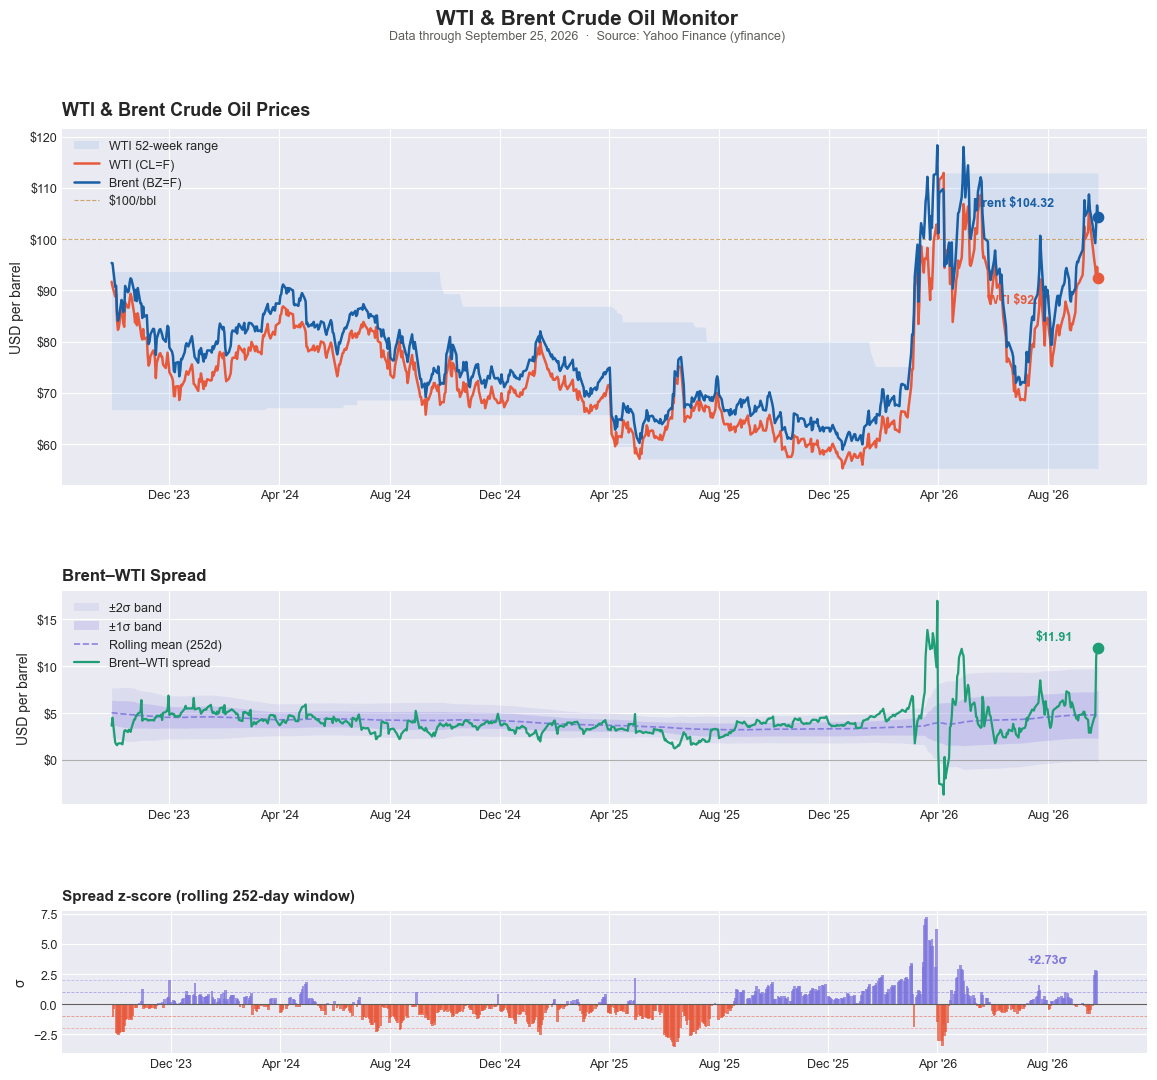


  Chart saved → c:\Users\mackt\Python Projects\oil_gas_tools\charts\wti_brent_monitor_September_25_2026.png


In [4]:
# ============================================================
# CELL 4 — Three-panel price and spread chart
# ============================================================
# Panel 1 (top)    : WTI and Brent price history
#                    with 52-week high/low band
# Panel 2 (middle) : WTI-Brent spread with rolling
#                    mean and ±1σ / ±2σ bands
# Panel 3 (bottom) : Spread z-score as a signal indicator
# ─────────────────────────────────────────────────────────────

# ── Subset to recent window for main chart ───────────────────
# Full history is used for spread stats but charts focus on
# the last 3 years for readability
cutoff_recent = pd.Timestamp.today() - pd.Timedelta(days=RECENT_DAYS)
df_plot = df_daily[df_daily["date"] >= cutoff_recent].copy()

# ── 52-week rolling high/low for price panel ─────────────────
df_daily["wti_52w_high"]   = df_daily["wti"].rolling(252).max()
df_daily["wti_52w_low"]    = df_daily["wti"].rolling(252).min()
df_daily["brent_52w_high"] = df_daily["brent"].rolling(252).max()
df_daily["brent_52w_low"]  = df_daily["brent"].rolling(252).min()

# Refilter plot subset after adding rolling columns
df_plot = df_daily[df_daily["date"] >= cutoff_recent].copy()

# ── Figure setup ─────────────────────────────────────────────
fig = plt.figure(figsize=(14, 12))
gs  = GridSpec(
    3, 1,
    figure       = fig,
    hspace       = 0.45,
    height_ratios= [2.5, 1.5, 1],
)

ax1 = fig.add_subplot(gs[0])   # price history
ax2 = fig.add_subplot(gs[1])   # spread
ax3 = fig.add_subplot(gs[2])   # spread z-score

latest     = df_daily.iloc[-1]
latest_wti = df_plot[df_plot["wti"].notna()].iloc[-1]

# ── Panel 1 — WTI and Brent prices ───────────────────────────
# 52-week band (WTI only for clarity)
ax1.fill_between(
    df_plot["date"],
    df_plot["wti_52w_low"],
    df_plot["wti_52w_high"],
    alpha = 0.12,
    color = "#378ADD",
    label = "WTI 52-week range",
    linewidth = 0,
)

# Price lines
ax1.plot(
    df_plot["date"], df_plot["wti"],
    color     = "#E8593C",
    linewidth = 1.8,
    label     = "WTI (CL=F)",
    zorder    = 4,
)
ax1.plot(
    df_plot["date"], df_plot["brent"],
    color     = "#185FA5",
    linewidth = 1.8,
    label     = "Brent (BZ=F)",
    zorder    = 4,
)

# Latest price dots
ax1.scatter(
    latest_wti["date"], latest_wti["wti"],
    color=  "#E8593C", s=55, zorder=6
)
ax1.scatter(
    latest_wti["date"], latest_wti["brent"],
    color="#185FA5", s=55, zorder=6
)

# Annotations
ax1.annotate(
    f"WTI ${latest_wti['wti']:.2f}",
    xy     = (latest_wti["date"], latest_wti["wti"]),
    xytext = (-80, -18),
    textcoords = "offset points",
    fontsize   = 9,
    color      = "#E8593C",
    fontweight = "bold",
)
ax1.annotate(
    f"Brent ${latest_wti['brent']:.2f}",
    xy     = (latest_wti["date"], latest_wti["brent"]),
    xytext = (-90, 8),
    textcoords = "offset points",
    fontsize   = 9,
    color      = "#185FA5",
    fontweight = "bold",
)

# $100 reference line
ax1.axhline(
    100, color="#BA7517", linewidth=0.8,
    linestyle="--", alpha=0.6, label="$100/bbl"
)

ax1.set_title(
    "WTI & Brent Crude Oil Prices",
    fontsize=13, fontweight="bold", loc="left", pad=10
)
ax1.set_ylabel("USD per barrel", fontsize=10)
ax1.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"${x:.0f}")
)
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b '%y"))
ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
ax1.tick_params(axis="both", labelsize=9)
ax1.legend(fontsize=9, loc="upper left",
           framealpha=0.85, edgecolor="none")

# ── Panel 2 — WTI-Brent spread ───────────────────────────────
# Rolling mean and ±1σ / ±2σ bands
ax2.fill_between(
    df_plot["date"],
    df_plot["spread_roll_mean"] - 2 * df_plot["spread_roll_std"],
    df_plot["spread_roll_mean"] + 2 * df_plot["spread_roll_std"],
    alpha=0.12, color="#7F77DD", linewidth=0,
    label="±2σ band",
)
ax2.fill_between(
    df_plot["date"],
    df_plot["spread_roll_mean"] - df_plot["spread_roll_std"],
    df_plot["spread_roll_mean"] + df_plot["spread_roll_std"],
    alpha=0.22, color="#7F77DD", linewidth=0,
    label="±1σ band",
)
ax2.plot(
    df_plot["date"], df_plot["spread_roll_mean"],
    color="#7F77DD", linewidth=1.2, linestyle="--",
    alpha=0.9, label="Rolling mean (252d)",
)
ax2.plot(
    df_plot["date"], df_plot["spread"],
    color="#1D9E75", linewidth=1.6,
    label="Brent–WTI spread", zorder=4,
)
ax2.axhline(
    0, color="var" if False else "#5F5E5A",
    linewidth=0.8, linestyle="-", alpha=0.5,
)

# Latest spread dot and annotation
ax2.scatter(
    latest_wti["date"], latest_wti["spread"],
    color="#1D9E75", s=55, zorder=6,
)
ax2.annotate(
    f"${latest_wti['spread']:.2f}",
    xy     = (latest_wti["date"], latest_wti["spread"]),
    xytext = (-45, 6),
    textcoords = "offset points",
    fontsize=9, color="#1D9E75", fontweight="bold",
)

ax2.set_title(
    "Brent–WTI Spread",
    fontsize=12, fontweight="bold", loc="left", pad=8
)
ax2.set_ylabel("USD per barrel", fontsize=10)
ax2.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"${x:.0f}")
)
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b '%y"))
ax2.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
ax2.tick_params(axis="both", labelsize=9)
ax2.legend(fontsize=9, loc="upper left",
           framealpha=0.85, edgecolor="none")

# ── Panel 3 — Spread z-score ──────────────────────────────────
# Color bars by direction — positive z = wide spread (purple)
#                           negative z = narrow/inverted (coral)
colors = df_plot["spread_z"].apply(
    lambda z: "#7F77DD" if z >= 0 else "#E8593C"
)
ax3.bar(
    df_plot["date"], df_plot["spread_z"],
    color=colors, width=3, alpha=0.75,
)
ax3.axhline(0,  color="#5F5E5A", linewidth=0.8)
ax3.axhline( 1, color="#7F77DD", linewidth=0.6,
             linestyle="--", alpha=0.6)
ax3.axhline(-1, color="#E8593C", linewidth=0.6,
             linestyle="--", alpha=0.6)
ax3.axhline( 2, color="#7F77DD", linewidth=0.6,
             linestyle="--", alpha=0.4)
ax3.axhline(-2, color="#E8593C", linewidth=0.6,
             linestyle="--", alpha=0.4)

# Latest z-score annotation
latest_z = df_plot["spread_z"].iloc[-1]
zscore_color = "#7F77DD" if latest_z >= 0 else "#E8593C"
ax3.annotate(
    f"{latest_z:+.2f}σ",
    xy     = (df_plot["date"].iloc[-1], latest_z),
    xytext = (-50, 6),
    textcoords = "offset points",
    fontsize=9, color=zscore_color, fontweight="bold",
)

ax3.set_title(
    "Spread z-score (rolling 252-day window)",
    fontsize=11, fontweight="bold", loc="left", pad=8
)
ax3.set_ylabel("σ", fontsize=10)
ax3.xaxis.set_major_formatter(mdates.DateFormatter("%b '%y"))
ax3.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
ax3.tick_params(axis="both", labelsize=9)

# ── Figure-level title and subtitle ─────────────────────────
latest_date_str = df_daily["date"].max().strftime("%B %d, %Y")
fig.suptitle(
    "WTI & Brent Crude Oil Monitor",
    fontsize=15, fontweight="bold", y=0.98,
)
fig.text(
    0.5, 0.955,
    f"Data through {latest_date_str}  ·  "
    f"Source: Yahoo Finance (yfinance)",
    ha="center", fontsize=9, color="#5F5E5A",
)

# ── Save and show ────────────────────────────────────────────
chart_path = (
    CHART_DIR /
    f"wti_brent_monitor_"
    f"{latest_date_str.replace(' ','_').replace(',','')}.png"
)
plt.savefig(chart_path, dpi=150, bbox_inches="tight",
            facecolor="white")
plt.show()
print(f"\n  Chart saved → {chart_path}")

In [5]:
# ============================================================
# CELL 5 — Load inventory signal and price comparison
# ============================================================
# Loads the most recent inventory data saved by the EIA Inventory Tracker (US and Cushing, OK; Tool 1), 
# aligns it to weekly prices, and plots the relationship
# between the inventory z-score and WTI price.

# This is the analytical bridge between the two tools - 
# does below-average inventory actually precede price rises?
# ─────────────────────────────────────────────────────────────


# ── Find most recent Tool 1 CSV ──────────────────────────────
# ── Fix: sort by modification time, not alphabetically ────────
import glob

inventory_files = sorted(
    glob.glob(str(DATA_DIR / "crude_inventory_*.csv")),
    key=lambda f: os.path.getmtime(f)
)

if not inventory_files:
    print("  !! No inventory CSV found in data/ folder.")
    print("  Run Tool 1 (eia_inventory_tracker.ipynb) first")
    print("  then rerun this cell.")
    raise FileNotFoundError("Inventory data not found.")

latest_inv_file = inventory_files[-1]
print(f"  Loading inventory data from:")
print(f"  {Path(latest_inv_file).name}")
print()

# ── Load and prepare inventory data ─────────────────────────
df_inv = pd.read_csv(latest_inv_file, parse_dates=["date"])
df_inv = df_inv.sort_values("date").reset_index(drop=True)

# Rename for clarity in merged DataFrame
df_inv = df_inv.rename(columns ={
    "deviation_std": "us_inv_z",
    "cush_deviation_std": "cush_inv_z",
    "deviation_mmbbl": "us_dev_mmbbl",
})

# ── Merge with weekly prices ──────────────────────────────────
# Inventory is weekly (Friday), prices resampled to weekly
# Use merge_asof for nearest-date matching to handle any
# slight date misalignment between EIA and market calendars
df_inv = df_inv.sort_values("date")
df_weekly_sorted = df_weekly.sort_values("date")

df_combined = pd.merge_asof(
    df_weekly_sorted,
    df_inv[["date", "us_inv_z", "cush_inv_z",
            "us_crude_stocks", "us_dev_mmbbl"]],
    on = "date",
    direction = "nearest",
    tolerance = pd.Timedelta(days=7)
)

df_combined = df_combined.dropna(
    subset=["wti", "us_inv_z"]
).reset_index(drop=True)

print(f"  Combined rows  : {len(df_combined)} weeks with "
      f"both price and inventory data")
print(f"  Date range     : {df_combined['date'].min().date()} → "
      f"{df_combined['date'].max().date()}")

# ── Correlation check ────────────────────────────────────────
# Quick look at whether inventory z-score has any relationship
# with subsequent price changes (1-week and 4-week forward)
df_combined["wti_fwd1w"] = df_combined["wti"].shift(-1)
df_combined["wti_fwd4w"] = df_combined["wti"].shift(-4)
df_combined["wti_ret1w"] = (
    (df_combined["wti_fwd1w"] - df_combined["wti"])
    / df_combined["wti"] * 100
)
df_combined["wti_ret4w"] = (
    (df_combined["wti_fwd4w"] - df_combined["wti"])
    / df_combined["wti"] * 100
)

corr_1w = df_combined["us_inv_z"].corr(
    df_combined["wti_ret1w"]
)
corr_4w = df_combined["us_inv_z"].corr(
    df_combined["wti_ret4w"]
)

print()
print("=" * 58)
print("  Inventory signal vs forward price returns")
print("=" * 58)
print(f"  Corr(inv_z, 1-week fwd return) : {corr_1w:+.3f}")
print(f"  Corr(inv_z, 4-week fwd return) : {corr_4w:+.3f}")
print()
print("  Interpretation:")
print("  Negative correlation = below-avg inventory (negative z)")
print("  tends to precede positive price returns — bullish signal")
print("  Positive correlation = above-avg inventory")
print("  tends to precede negative price returns — bearish signal")
print("=" * 58)

  Loading inventory data from:
  crude_inventory_September_18_2026.csv

  Combined rows  : 40 weeks with both price and inventory data
  Date range     : 2025-12-26 → 2026-09-25

  Inventory signal vs forward price returns
  Corr(inv_z, 1-week fwd return) : +0.061
  Corr(inv_z, 4-week fwd return) : -0.033

  Interpretation:
  Negative correlation = below-avg inventory (negative z)
  tends to precede positive price returns — bullish signal
  Positive correlation = above-avg inventory
  tends to precede negative price returns — bearish signal


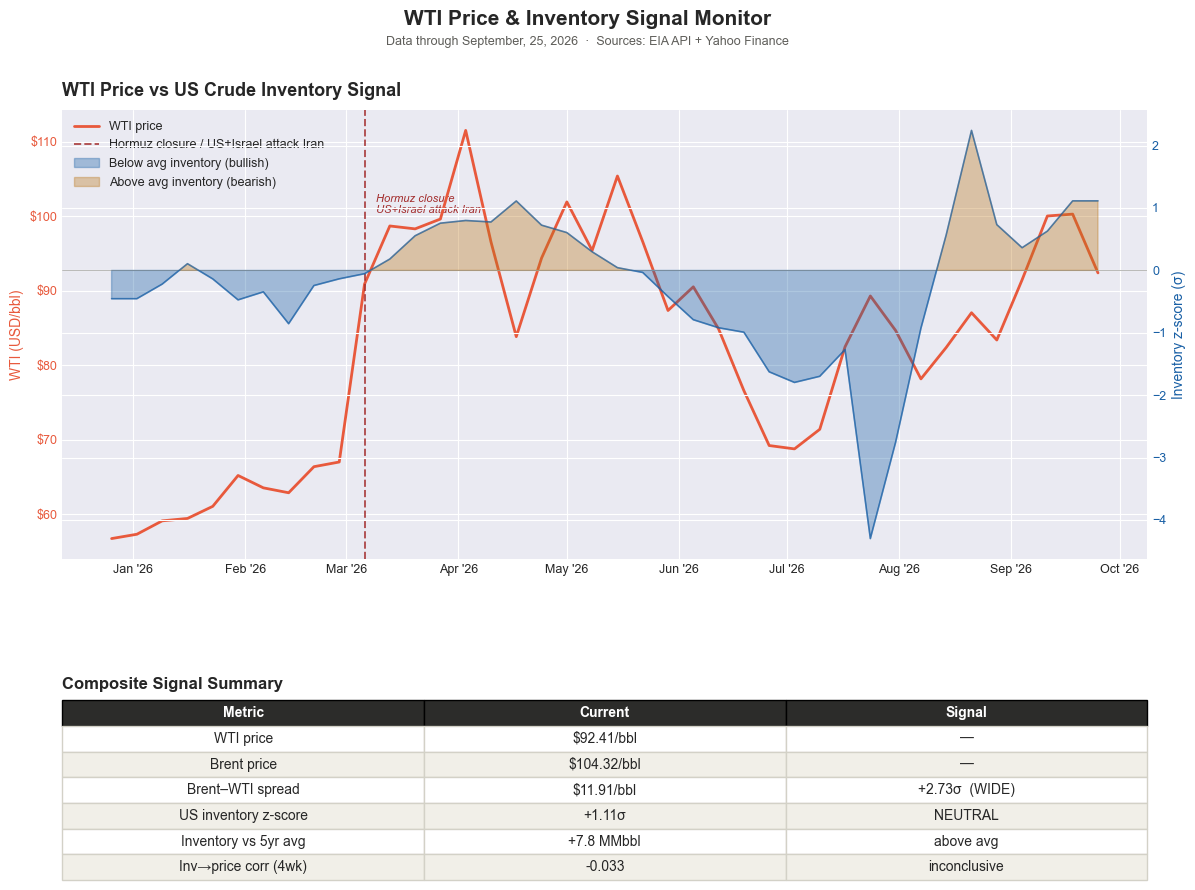


  Chart saved → c:\Users\mackt\Python Projects\oil_gas_tools\charts\price_inventory_overlay_September_25_2026.png


In [6]:
# ============================================================
# CELL 6 — Overlay chart: WTI price vs inventory signal
# ============================================================
# Two-panel chart:
#   Top    : WTI price with inventory z-score overlaid
#            on a secondary axis
#   Bottom : Signal dashboard summary
# ─────────────────────────────────────────────────────────────

# ── Staleness check — runs before dashboard table ─────────────
combined_wti  = df_combined["wti"].iloc[-1]
combined_date = df_combined["date"].iloc[-1].strftime("%b %d")
current_wti   = df_daily["wti"].iloc[-1]
current_date  = df_daily["date"].iloc[-1].strftime("%b %d")

if abs(current_wti - combined_wti) > 5:
    print("!" * 58)
    print(f"  STALENESS WARNING")
    print(f"  Dashboard WTI : ${combined_wti:.2f} "
          f"(inventory cutoff {combined_date})")
    print(f"  Current WTI   : ${current_wti:.2f} "
          f"(cache as of {current_date})")
    print(f"  Gap           : "
          f"${abs(current_wti - combined_wti):.2f}")
    print(f"  Action        : Run Tool 1 first, "
          f"then rerun Tool 2")
    print("!" * 58)
    print()


# ── Build the overlay chart ──────────────────────────────────
fig, axes = plt.subplots(
    2, 1,
    figsize = (14, 10),
    gridspec_kw = {"hspace": 0.45, "height_ratios": [2.5, 1]},
)

ax_price = axes[0]
ax_inv = ax_price.twinx() # secondary y-axis for inventory z score

# ── WTI price line (primary axis) ───────────────────────────
ax_price.plot(
    df_combined["date"], df_combined["wti"],
    color = "#E8593C",
    linewidth = 2.0,
    label = "WTI price",
    zorder = 4,
)

# Shade the geopolitical spike period
# Find where WTI crossed $80 on the way up in 2026
spike_start = df_combined[
    (df_combined["date"] >= "2026-02-01") &
    (df_combined["wti"] > 75)
]["date"].min()

if pd.notna(spike_start):
    ax_price.axvline(
        x         = spike_start,
        color     = "#A32D2D",
        linewidth = 1.4,
        linestyle = "--",
        alpha     = 0.8,
        label     = "Hormuz closure / US+Israel attack Iran",
        zorder    = 5,
    )
    ax_price.annotate(
        "Hormuz closure\nUS+Israel attack Iran",
        xy         = (spike_start,
                      df_combined["wti"].max() * 0.9),
        xytext     = (8, 0),
        textcoords = "offset points",
        fontsize   = 8,
        color      = "#A32D2D",
        fontstyle  = "italic",
        ha         = "left",
    )

ax_price.set_ylabel("WTI (USD/bbl)", fontsize=10,
                    color = "#E8593C")
ax_price.tick_params(axis="y", labelcolor="#E8593C",
                     labelsize=9)
ax_price.yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f"${x:.0f}")
)

# ── Inventory z-score (secondary axis) ──────────────────────
# Plot as filled area so it's clearly secondary
ax_inv.fill_between(
    df_combined["date"],
    0,
    df_combined["us_inv_z"],
    where = df_combined["us_inv_z"] < 0,
    alpha = 0.35,
    color = "#185FA5",
    label = "Below avg inventory (bullish)",
    interpolate = True,
)
ax_inv.fill_between(
    df_combined["date"],
    0,
    df_combined["us_inv_z"],
    where  = df_combined["us_inv_z"] >= 0,
    alpha  = 0.35,
    color  = "#BA7517",
    label  = "Above avg inventory (bearish)",
    interpolate = True,
)
ax_inv.plot(
    df_combined["date"],
    df_combined["us_inv_z"],
    color = "#185FA5",
    linewidth = 1.2,
    alpha = 0.7,
    zorder = 3
)
ax_inv.axhline(0, color="#5F5E5A", linewidth=0.6,
               alpha=0.5)
ax_inv.set_ylabel("Inventory z-score (σ)", fontsize=10,
                  color="#185FA5")
ax_inv.tick_params(axis="y", labelcolor="#185FA5",
                    labelsize=9)

# ── Combined legend ──────────────────────────────────────────
lines1, labels1 = ax_price.get_legend_handles_labels()
lines2, labels2 = ax_inv.get_legend_handles_labels()
ax_price.legend(
    lines1 + lines2, labels1 + labels2,
    fontsize=9, loc="upper left",
    framealpha=0.85, edgecolor="none",
)

ax_price.set_title(
    "WTI Price vs US Crude Inventory Signal",
    fontsize=13, fontweight="bold", loc="left", pad=10,
)
ax_price.xaxis.set_major_formatter(
    mdates.DateFormatter("%b '%y")
)
ax_price.xaxis.set_major_locator(
    mdates.MonthLocator(interval=1)
)
ax_price.tick_params(axis="x", labelsize=9)

# ── Bottom panel: signal summary table ───────────────────────
ax_table = axes[1]
ax_table.axis("off")

# Current readings
latest_combined = df_combined.iloc[-1]
latest_price = df_combined[
    df_combined["wti"].notna()
].iloc[-1]

# Price momentum
ret_1w = df_combined["wti_ret1w"].iloc[-2] # last complete
ret_4w = df_combined["wti_ret4w"].iloc[-5] # last complete

# Spread current
latest_spread = df_daily["spread"].iloc[-1]
latest_spread_z = df_daily["spread_z"].iloc[-1]

# Build table data
table_data = [
    ["Metric", "Current", "Signal"],
    ["WTI price",
     f"${latest_price['wti']:.2f}/bbl",
     "—"],
    ["Brent price",
     f"${latest_price['brent']:.2f}/bbl",
     "—"],
    ["Brent–WTI spread",
     f"${latest_spread:.2f}/bbl",
     f"{latest_spread_z:+.2f}σ  "
     f"({'WIDE' if latest_spread_z > 1 else 'NORMAL'})"],
    ["US inventory z-score",
     f"{latest_combined['us_inv_z']:+.2f}σ",
     "mild BULLISH" if latest_combined['us_inv_z'] < -0.5
     else "NEUTRAL"],
    ["Inventory vs 5yr avg",
     f"{latest_combined['us_dev_mmbbl']:+.1f} MMbbl",
     "below avg" if latest_combined['us_dev_mmbbl'] < 0
     else "above avg"],
    ["Inv→price corr (4wk)",
     f"{corr_4w:+.3f}",
     "directionally bullish" if corr_4w < -0.3
     else "inconclusive"],
]

table = ax_table.table(
    cellText = table_data[1:],
    colLabels = table_data[0],
    cellLoc = "center",
    loc = "center",
    bbox = [0, 0, 1, 1],
)
table.auto_set_font_size(False)
table.set_fontsize(10)

# Style header row
for j in range(3):
    table[0, j].set_facecolor("#2C2C2A")
    table[0, j].set_text_props(color="white",
                               fontweight="bold")

# Style alternating rows
for i in range(1, len(table_data)):
    for j in range(3):
        if i % 2 == 0:
            table[i, j].set_facecolor("#F1EFE8")
        table[i, j].set_edgecolor("#D3D1C7")

ax_table.set_title(
    "Composite Signal Summary",
    fontsize=12, fontweight="bold",
    loc="left", pad=8
)

# ── Figure title ─────────────────────────────────────────────
latest_date_str = df_daily["date"].max().strftime("%B, %d, %Y")
fig.suptitle(
    "WTI Price & Inventory Signal Monitor",
    fontsize=15, fontweight="bold", y=0.98,
)
fig.text(
    0.5, 0.945,
    f"Data through {latest_date_str}  ·  "
    f"Sources: EIA API + Yahoo Finance",
    ha="center", fontsize=9, color="#5F5E5A",
)
# ── Save ─────────────────────────────────────────────────────
chart_path = (
    CHART_DIR /
    f"price_inventory_overlay_"
    f"{latest_date_str.replace(' ','_').replace(',','')}.png"
)
plt.savefig(
    chart_path, dpi=150,
    bbox_inches="tight", facecolor="white",
)
plt.show()
print(f"\n  Chart saved → {chart_path}")


In [7]:
# ============================================================
# CELL 7 — Save data and wrap up
# ============================================================


# Save combined dataset
csv_filename = (
    f"price_inventory_combined_"
    f"{latest_date_str.replace(' ','_').replace(',','')}.csv"
)
csv_path = DATA_DIR / csv_filename

save_cols = [
    "date", "wti", "brent", "spread",
    "spread_roll_mean", "spread_roll_std", "spread_z",
    "us_inv_z", "us_crude_stocks", "us_dev_mmbbl",
]
df_combined[[c for c in save_cols
             if c in df_combined.columns]].to_csv(
    csv_path, index=False
)
print(f"  Data saved → {csv_path}")

# ── Save weekly commentary log ────────────────────────────────
commentary_path = DATA_DIR / "wti_brent_commentary_log.txt"

latest_combined = df_combined.iloc[-1]
latest_spread   = df_daily["spread"].iloc[-1]
latest_spread_z = df_daily["spread_z"].iloc[-1]
latest_wti_p    = df_daily["wti"].iloc[-1]
latest_brent_p  = df_daily["brent"].iloc[-1]

spread_signal = (
    "WIDE — geopolitical/logistical premium"
    if latest_spread_z > 1.5
    else "ELEVATED — above historical norm"
    if latest_spread_z > 0.5
    else "NORMAL — within historical range"
    if latest_spread_z > -0.5
    else "NARROW — WTI at premium to historical norm"
)

inv_signal = (
    "BULLISH" if latest_combined["us_inv_z"] < -0.5
    else "NEUTRAL"
    if abs(latest_combined["us_inv_z"]) <= 0.5
    else "BEARISH"
)

commentary_entry = f"""
{'=' * 60}
WTI & BRENT PRICE MONITOR COMMENTARY
Run date  : {dt.date.today().strftime('%B %d, %Y')}
Data date : {latest_date_str}
{'=' * 60}

METRICS SNAPSHOT
  WTI price           : ${latest_wti_p:.2f}/bbl
  Brent price         : ${latest_brent_p:.2f}/bbl
  Brent-WTI spread    : ${latest_spread:.2f}/bbl
  Spread z-score      : {latest_spread_z:+.2f} sigma
  Spread signal       : {spread_signal}

  US inventory z-score: {latest_combined['us_inv_z']:+.2f} sigma
  US stocks vs 5yr avg: {latest_combined['us_dev_mmbbl']:+.1f} MMbbl
  Inventory signal    : {inv_signal}

  Inv->price corr 1wk : {corr_1w:+.3f}
  Inv->price corr 4wk : {corr_4w:+.3f}

PLAIN ENGLISH SUMMARY
  As of {latest_date_str}, WTI crude was trading at
  ${latest_wti_p:.2f}/bbl and Brent at ${latest_brent_p:.2f}/bbl.
  The Brent-WTI spread stood at ${latest_spread:.2f}/bbl
  ({latest_spread_z:+.2f} sigma vs rolling mean) — {spread_signal.lower()}.
  US crude inventory z-score was {latest_combined['us_inv_z']:+.2f} sigma,
  with stocks {abs(latest_combined['us_dev_mmbbl']):.1f} MMbbl
  {'below' if latest_combined['us_dev_mmbbl'] < 0 else 'above'}
  the five-year seasonal average.
  The 4-week inventory-to-price correlation of {corr_4w:+.3f}
  is {'directionally bullish' if corr_4w < -0.3 else 'inconclusive'}.

"""

with open(commentary_path, "a", encoding="utf-8") as f:
    f.write(commentary_entry)

print(f"  Commentary logged -> {commentary_path.name}")

# Next refresh
today         = dt.date.today()
days_to_wed   = (2 - today.weekday()) % 7
next_wednesday = (today + dt.timedelta(days=days_to_wed)
                  if days_to_wed > 0 else today)

print()
print("=" * 58)
print("  TOOL 2 COMPLETE")
print("=" * 58)
print(f"""
  What this notebook built:
  ──────────────────────────────────────────────────
  ✓ Pulled {len(df_daily):,} days of WTI + Brent price history
  ✓ Built caching system — refreshes in <2 seconds
  ✓ Calculated Brent-WTI spread + rolling z-score
  ✓ 3-panel price/spread/signal chart
  ✓ Loaded Tool 1 inventory signal from CSV
  ✓ Overlaid inventory z-score against WTI price
  ✓ Computed inventory → price correlation
  ✓ Saved combined dataset → data/

  To refresh after market close any day:
  ──────────────────────────────────────────────────
  1. Kernel → Restart and Run All
  2. Cache auto-updates with new trading days only
  3. Next EIA inventory release: Wednesday
     {next_wednesday} at 10:30am ET
  4. Run Tool 1 first on Wednesdays, then Tool 2
     to get the updated overlay chart

  Key signals to watch:
  ──────────────────────────────────────────────────
  · Spread z-score normalizing toward 0 = Hormuz
    risk premium being priced out (bearish)
  · Inventory z-score turning positive = supply
    rebuilding, bearish for WTI
  · Spread z-score staying > +2σ = market still
    pricing sustained disruption risk (bullish)
""")
print("=" * 58)

  Data saved → c:\Users\mackt\Python Projects\oil_gas_tools\data\price_inventory_combined_September_25_2026.csv
  Commentary logged -> wti_brent_commentary_log.txt

  TOOL 2 COMPLETE

  What this notebook built:
  ──────────────────────────────────────────────────
  ✓ Pulled 4,967 days of WTI + Brent price history
  ✓ Built caching system — refreshes in <2 seconds
  ✓ Calculated Brent-WTI spread + rolling z-score
  ✓ 3-panel price/spread/signal chart
  ✓ Loaded Tool 1 inventory signal from CSV
  ✓ Overlaid inventory z-score against WTI price
  ✓ Computed inventory → price correlation
  ✓ Saved combined dataset → data/

  To refresh after market close any day:
  ──────────────────────────────────────────────────
  1. Kernel → Restart and Run All
  2. Cache auto-updates with new trading days only
  3. Next EIA inventory release: Wednesday
     2026-09-30 at 10:30am ET
  4. Run Tool 1 first on Wednesdays, then Tool 2
     to get the updated overlay chart

  Key signals to watch:
  ───────